In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Verify data is where it should be
data_dir = Path("data")
expected_files = [
    "poker-hand.names",
    "poker-hand-training-true.data",
    "poker-hand-testing.data"
]
for filename in expected_files:
    file_path = data_dir / filename
    if file_path.exists():
        print(f"FOUND: {file_path} ({file_path.stat().st_size:,} bytes)")
    else:
        print(f"MISSING: {file_path}")

# Verify documentation
names_path = data_dir / "poker-hand.names"
with open(names_path, "r", encoding="cp1252") as file:
    documentation = file.read()
print(documentation[:10000])

In [ ]:
columns = [
    "S1", "C1",
    "S2", "C2",
    "S3", "C3",
    "S4", "C4",
    "S5", "C5",
    "CLASS"
]

# Load the two datasets and check them
train_df = pd.read_csv(
    data_dir / "poker-hand-training-true.data",
    header=None,
    names=columns
)

test_df = pd.read_csv(
    data_dir / "poker-hand-testing.data",
    header=None,
    names=columns
)

print("Training dataset shape:", train_df.shape)
print("Testing dataset shape:", test_df.shape)

print("\nFirst five training observations:")
display(train_df.head())

print("\nFirst five testing observations:")
display(test_df.head())

In [ ]:
# Verify data quality
print("Training data types:")
print(train_df.dtypes)

print("\nMissing values in training data:")
print(train_df.isnull().sum().sum())

print("\nMissing values in testing data:")
print(test_df.isnull().sum().sum())

print("\nDuplicate rows in training data:", train_df.duplicated().sum())
print("Duplicate rows in testing data:", test_df.duplicated().sum())

print("\nTraining data ranges:")
print(train_df.agg(["min", "max"]).T)

In [ ]:
# Poker hands (not poker face)
hand_labels = {
    0: "Nothing",
    1: "One Pair",
    2: "Two Pairs",
    3: "Three of a Kind",
    4: "Straight",
    5: "Flush",
    6: "Full House",
    7: "Four of a Kind",
    8: "Straight Flush",
    9: "Royal Flush"
}

# Verify that the labels cover all observed classes
observed_classes = sorted(train_df["CLASS"].unique())

print("Observed classes:", observed_classes)
print("Number of classes:", len(observed_classes))

print("\nClass labels:")
for class_id, label in hand_labels.items():
    print(f"{class_id}: {label}")

In [ ]:
# Compare class distributions, visualize the imbalance
train_counts = train_df["CLASS"].value_counts().sort_index()
test_counts = test_df["CLASS"].value_counts().sort_index()

class_distribution = pd.DataFrame({
    "Hand": [hand_labels[i] for i in range(10)],
    "Training Count": train_counts.reindex(range(10), fill_value=0),
    "Training %": (
        train_counts.reindex(range(10), fill_value=0)
        / len(train_df) * 100
    ),
    "Testing Count": test_counts.reindex(range(10), fill_value=0),
    "Testing %": (
        test_counts.reindex(range(10), fill_value=0)
        / len(test_df) * 100
    )
})

display(
    class_distribution.style.format({
        "Training %": "{:.3f}%",
        "Testing %": "{:.3f}%"
    })
)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

class_ids = range(10)
labels = [hand_labels[i] for i in class_ids]

axes[0].bar(
    labels,
    train_counts.reindex(class_ids, fill_value=0),
    color="steelblue"
)
axes[0].set_title("Training Set: Class Distribution")
axes[0].set_ylabel("Number of Hands")
axes[0].tick_params(axis="x", rotation=60)

axes[1].bar(
    labels,
    test_counts.reindex(class_ids, fill_value=0),
    color="darkorange"
)
axes[1].set_title("Testing Set: Class Distribution")
axes[1].set_ylabel("Number of Hands (log scale)")
axes[1].set_yscale("log")
axes[1].tick_params(axis="x", rotation=60)

plt.tight_layout()
plt.show()

In [ ]:
# Separate features (X) from the target (y)
feature_columns = [
    "S1", "C1",
    "S2", "C2",
    "S3", "C3",
    "S4", "C4",
    "S5", "C5"
]

X_train = train_df[feature_columns].copy()
y_train = train_df["CLASS"].copy()

X_test = test_df[feature_columns].copy()
y_test = test_df["CLASS"].copy()

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

In [ ]:
# Check duplicate observations reported earlier
train_duplicate_count = train_df.duplicated().sum()
test_duplicate_count = test_df.duplicated().sum()

train_conflicting_labels = (
    train_df.groupby(feature_columns)["CLASS"]
    .nunique()
    .gt(1)
    .sum()
)

test_conflicting_labels = (
    test_df.groupby(feature_columns)["CLASS"]
    .nunique()
    .gt(1)
    .sum()
)

print("Exact duplicate training rows:", train_duplicate_count)
print("Exact duplicate testing rows:", test_duplicate_count)

print(
    "Training card combinations with conflicting labels:",
    train_conflicting_labels
)

print(
    "Testing card combinations with conflicting labels:",
    test_conflicting_labels
)

In [ ]:
# Suits are categorical codes from 1 to 4
# Ranks are categorical values from 1 to 13 even if stored as integers
# Poker hand categories depend on a combination of cards like matching rank or
# identical suits for each card.

# Two Naive Bayes approaches are worthwhile
# Gaussian takes the original 10 numeric columns and provides a simple baseline
# Multinomial takes one-hot encoded suit/rank indicators and treats them as
# discrete categories.

In [46]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

# Gaussian Naive Bayes first
gaussian_model = GaussianNB()
gaussian_model.fit(X_train, y_train)
gaussian_predictions = gaussian_model.predict(X_test)
gaussian_accuracy = accuracy_score(y_test, gaussian_predictions)
gaussian_balanced_accuracy = balanced_accuracy_score(
    y_test, gaussian_predictions
)

print(f"Accuracy:          {gaussian_accuracy:.4f}")
print(f"Balanced accuracy: {gaussian_balanced_accuracy:.4f}")

print("\nClassification report:")
print(
    classification_report(
        y_test,
        gaussian_predictions,
        labels=list(range(10)),
        target_names=[hand_labels[i] for i in range(10)],
        zero_division=0
    )
)

Accuracy:          0.5012
Balanced accuracy: 0.1000

Classification report:
                 precision    recall  f1-score   support

        Nothing       0.50      1.00      0.67    501209
       One Pair       0.00      0.00      0.00    422498
      Two Pairs       0.00      0.00      0.00     47622
Three of a Kind       0.00      0.00      0.00     21121
       Straight       0.00      0.00      0.00      3885
          Flush       0.00      0.00      0.00      1996
     Full House       0.00      0.00      0.00      1424
 Four of a Kind       0.00      0.00      0.00       230
 Straight Flush       0.00      0.00      0.00        12
    Royal Flush       0.00      0.00      0.00         3

       accuracy                           0.50   1000000
      macro avg       0.05      0.10      0.07   1000000
   weighted avg       0.25      0.50      0.33   1000000



In [ ]:
# Gaussian treated these as normally distributed even if these are discrete
# Poker hands also depend on card combinations and some categories don't show.

In [47]:
# Multinomial Naive Bayes - what we'll actually work with
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

X_train_encoded = encoder.fit_transform(X_train)
X_test_encoded = encoder.transform(X_test)

print("Original training shape:", X_train.shape)
print("Encoded training shape:", X_train_encoded.shape)
print("Original testing shape:", X_test.shape)
print("Encoded testing shape:", X_test_encoded.shape)
print("\nAll encoded values are nonnegative:",
      (X_train_encoded >= 0).all())

multinomial_model = MultinomialNB()
multinomial_model.fit(X_train_encoded, y_train)
multinomial_predictions = multinomial_model.predict(X_test_encoded)
multinomial_accuracy = accuracy_score(
    y_test, multinomial_predictions
)
multinomial_balanced_accuracy = balanced_accuracy_score(
    y_test, multinomial_predictions
)

print(f"Accuracy:          {multinomial_accuracy:.4f}")
print(f"Balanced accuracy: {multinomial_balanced_accuracy:.4f}")
print("\nClassification report:")
print(
    classification_report(
        y_test,
        multinomial_predictions,
        labels=list(range(10)),
        target_names=[hand_labels[i] for i in range(10)],
        zero_division=0
    )
)

Original training shape: (25010, 10)
Encoded training shape: (25010, 85)
Original testing shape: (1000000, 10)
Encoded testing shape: (1000000, 85)

All encoded values are nonnegative: True
Accuracy:          0.4940
Balanced accuracy: 0.0996

Classification report:
                 precision    recall  f1-score   support

        Nothing       0.50      0.93      0.65    501209
       One Pair       0.41      0.07      0.11    422498
      Two Pairs       0.00      0.00      0.00     47622
Three of a Kind       0.00      0.00      0.00     21121
       Straight       0.00      0.00      0.00      3885
          Flush       0.00      0.00      0.00      1996
     Full House       0.00      0.00      0.00      1424
 Four of a Kind       0.00      0.00      0.00       230
 Straight Flush       0.00      0.00      0.00        12
    Royal Flush       0.00      0.00      0.00         3

       accuracy                           0.49   1000000
      macro avg       0.09      0.10      0.08  

In [ ]:
# Compare predicted distributions
prediction_distribution = pd.DataFrame({
    "Actual Test Count": y_test.value_counts().reindex(
        range(10), fill_value=0
    ),
    "Gaussian Predictions": pd.Series(
        gaussian_predictions
    ).value_counts().reindex(range(10), fill_value=0),
    "Multinomial Predictions": pd.Series(
        multinomial_predictions
    ).value_counts().reindex(range(10), fill_value=0)
})

prediction_distribution.index = [
    f"{i}: {hand_labels[i]}" for i in range(10)
]

display(prediction_distribution)

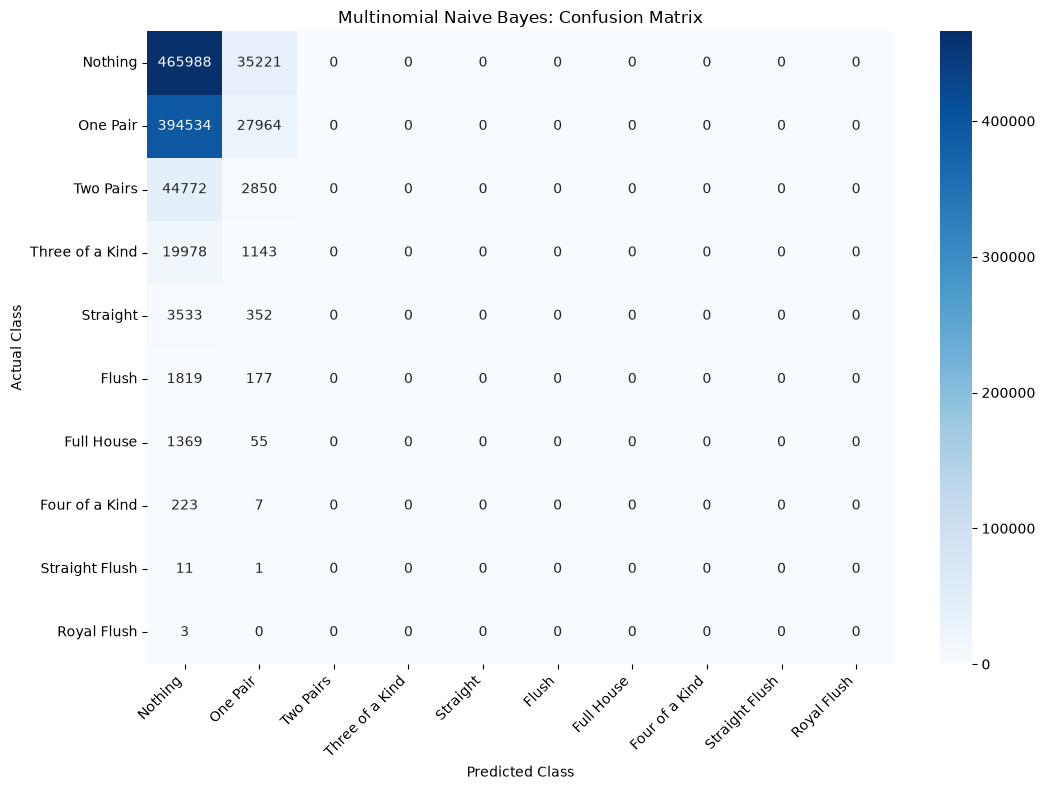

In [48]:
# Confusion matrix
cm = confusion_matrix(
    y_test,
    multinomial_predictions,
    labels=list(range(10))
)

plt.figure(figsize=(11, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[hand_labels[i] for i in range(10)],
    yticklabels=[hand_labels[i] for i in range(10)]
)

plt.title("Multinomial Naive Bayes: Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [49]:
# MultinomialNB with uniform class priors
uniform_priors = np.full(10, 1 / 10)

multinomial_uniform_model = MultinomialNB(
    class_prior=uniform_priors
)

multinomial_uniform_model.fit(X_train_encoded, y_train)

uniform_predictions = multinomial_uniform_model.predict(
    X_test_encoded
)

uniform_accuracy = accuracy_score(y_test, uniform_predictions)

uniform_balanced_accuracy = balanced_accuracy_score(
    y_test, uniform_predictions
)

print(f"Accuracy:          {uniform_accuracy:.4f}")
print(f"Balanced accuracy: {uniform_balanced_accuracy:.4f}")

print("\nClassification report:")
print(
    classification_report(
        y_test,
        uniform_predictions,
        labels=list(range(10)),
        target_names=[hand_labels[i] for i in range(10)],
        zero_division=0
    )
)

Accuracy:          0.0542
Balanced accuracy: 0.2116

Classification report:
                 precision    recall  f1-score   support

        Nothing       0.52      0.05      0.09    501209
       One Pair       0.40      0.05      0.09    422498
      Two Pairs       0.04      0.09      0.06     47622
Three of a Kind       0.02      0.13      0.04     21121
       Straight       0.01      0.33      0.01      3885
          Flush       0.00      0.21      0.01      1996
     Full House       0.00      0.17      0.00      1424
 Four of a Kind       0.00      0.09      0.00       230
 Straight Flush       0.00      0.00      0.00        12
    Royal Flush       0.00      1.00      0.00         3

       accuracy                           0.05   1000000
      macro avg       0.10      0.21      0.03   1000000
   weighted avg       0.43      0.05      0.09   1000000



In [ ]:
# Lets split the original training data into smaller training/testing subsets
from sklearn.model_selection import train_test_split

X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.25,
    random_state=42,
    stratify=y_train
)

print("Subtraining observations:", len(X_subtrain))
print("Validation observations:", len(X_val))

print("\nClass counts in validation set:")
print(y_val.value_counts().sort_index())

In [ ]:
validation_encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

X_subtrain_encoded = validation_encoder.fit_transform(X_subtrain)
X_val_encoded = validation_encoder.transform(X_val)

print("Encoded subtraining shape:", X_subtrain_encoded.shape)
print("Encoded validation shape:", X_val_encoded.shape)

In [ ]:
validation_models = {
    "Empirical priors": MultinomialNB(),
    "Uniform priors": MultinomialNB(
        class_prior=np.full(10, 0.1)
    )
}

validation_results = []

for name, model in validation_models.items():
    model.fit(X_subtrain_encoded, y_subtrain)
    predictions = model.predict(X_val_encoded)

    validation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Balanced Accuracy": balanced_accuracy_score(
            y_val, predictions
        )
    })

validation_results_df = pd.DataFrame(validation_results)

display(
    validation_results_df.style.format({
        "Accuracy": "{:.4f}",
        "Balanced Accuracy": "{:.4f}"
    })
)

In [ ]:
# Rank patterns by poker-hand class
rank_columns = ["C1", "C2", "C3", "C4", "C5"]

rank_means = train_df.groupby("CLASS")[rank_columns].mean()

rank_means.index = [
    hand_labels[class_id] for class_id in rank_means.index
]

display(rank_means.round(2))

In [ ]:
# Rank distribtions for common hand categories
common_classes = [0, 1, 2, 3]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes = axes.flatten()

for ax, class_id in zip(axes, common_classes):
    subset = train_df.loc[train_df["CLASS"] == class_id, rank_columns]

    rank_values = subset.to_numpy().ravel()

    sns.histplot(
        rank_values,
        bins=np.arange(0.5, 14.5, 1),
        discrete=True,
        ax=ax
    )

    ax.set_title(f"Rank Distribution: {hand_labels[class_id]}")
    ax.set_xlabel("Card Rank")
    ax.set_ylabel("Number of Cards")
    ax.set_xticks(range(1, 14))

plt.tight_layout()
plt.show()

In [ ]:
# Rank matching within hands
rank_columns = ["C1", "C2", "C3", "C4", "C5"]

train_df["distinct_ranks"] = train_df[rank_columns].nunique(axis=1)

train_df["has_repeated_rank"] = (
    train_df["distinct_ranks"] < 5
)

rank_pattern_summary = (
    train_df.groupby("CLASS")
    .agg(
        hands=("CLASS", "size"),
        average_distinct_ranks=("distinct_ranks", "mean"),
        repeated_rank_fraction=("has_repeated_rank", "mean")
    )
)

rank_pattern_summary.index = [
    hand_labels[class_id] for class_id in rank_pattern_summary.index
]

display(
    rank_pattern_summary.style.format({
        "average_distinct_ranks": "{:.2f}",
        "repeated_rank_fraction": "{:.1%}"
    })
)

In [ ]:
# Suit matching within hands
suit_columns = ["S1", "S2", "S3", "S4", "S5"]

train_df["distinct_suits"] = train_df[suit_columns].nunique(axis=1)

suit_pattern_summary = (
    train_df.groupby("CLASS")
    .agg(
        hands=("CLASS", "size"),
        average_distinct_suits=("distinct_suits", "mean"),
        all_same_suit_fraction=(
            "distinct_suits",
            lambda values: (values == 1).mean()
        )
    )
)

suit_pattern_summary.index = [
    hand_labels[class_id] for class_id in suit_pattern_summary.index
]

display(
    suit_pattern_summary.style.format({
        "average_distinct_suits": "{:.2f}",
        "all_same_suit_fraction": "{:.1%}"
    })
)